# Exercício 1

1. Gere uma amostra de tamanho $K$ de uma variável com distribuição binomial negativa com parâmetros $p$ $r$ utilizando os três métodos vistos em sala: via Bernoullis, via soma de geométricas, via recursão.
2. Compare com uma amostra gerada pelo numpy usando histogramas.
3. Compare o tempo dos três métodos como visto nos labs anteriores.



Tempo via Bernoullis:        0.3609 s
Tempo via Soma Geométricas: 0.1407 s
Tempo via Recursão:         0.0437 s


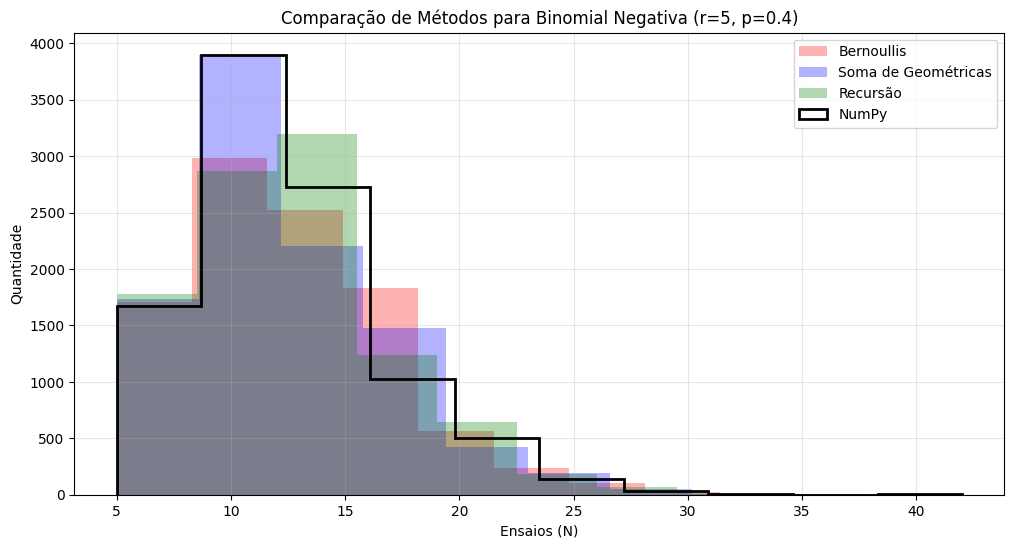

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

K = 10000
r = 5         # Número de sucessos desejados
p = 0.4       # Probabilidade de sucesso

# Método Bernoulli
def bin_neg_bernoulli(r, p):
  s = 0
  n = 0
  while s < r:
      n += 1
      if np.random.uniform(0, 1) <= p:
          s += 1
  return n

# Método Inversão
def bin_neg_geometricas(r, p):
  u = np.random.uniform(0, 1, size=r)

  return np.sum((np.floor(np.log(u) / np.log(1 - p)) + 1))

# Método Inversão Recursiva
def bin_neg_recursivo(r, p):
    u = np.random.uniform(0, 1)
    n = r
    pn = p**r
    F = pn
    while u > F:
        pn *= (n / (n - r + 1)) * (1 - p)
        F += pn
        n += 1
    return n

# Timestamping
amostra_bern = []
amostra_geom = []
amostra_rec = []
amostra_np = np.random.negative_binomial(r, p, size=K) + r #negative_binomial retorna numero de fracassos

# Bernoulli
t0 = time.time()

for _ in range(K):
  amostra_bern.append(bin_neg_bernoulli(r, p))

t_bern = time.time() - t0

# Método 2: Soma de Geométricas
t0 = time.time()

for _ in range(K):
  amostra_geom.append(bin_neg_geometricas(r, p))

t_geom = time.time() - t0

# Método 3: Recursão
t0 = time.time()

for _ in range(K):
  amostra_rec.append(bin_neg_recursivo(r, p))

t_rec = time.time() - t0

# Comparação de Tempos de Execução
print("Tempo via Bernoullis:        {:.4f} s".format(t_bern))
print("Tempo via Soma Geométricas: {:.4f} s".format(t_geom))
print("Tempo via Recursão:         {:.4f} s".format(t_rec))

# Comparação de Histogramas
# Referência: https://matplotlib.org/stable/gallery/statistics/histogram_multihist.html
plt.figure(figsize=(12, 6))

plt.hist(amostra_bern, alpha=0.3, label='Bernoullis', color='red')
plt.hist(amostra_geom, alpha=0.3, label='Soma de Geométricas', color='blue')
plt.hist(amostra_rec, alpha=0.3, label='Recursão', color='green')
plt.hist(amostra_np, histtype='step', linewidth=2, label='NumPy', color='black')

plt.title("Comparação de Métodos para Binomial Negativa (r={}, p={})".format(r,p))
plt.xlabel("Ensaios (N)")
plt.ylabel("Quantidade")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Exercício 2

1.  Gere uma amostra de tamanho $K$ de uma variável aleatória com distribuição hipergeométrica com parâmetros $M,N,n$ utilizando o método de embaralhamento de Fisher–Yates.
2.  No método de Fisher-Yates, no passo (a), a gente amostra um ponto para troca entre $i$ e $N$. Pense em qual seria o problema caso a gente sempre amostrasse entre $1$ e $N$. Compare o resultado final usando essas duas versões e uma amostra gerada pelo numpy.

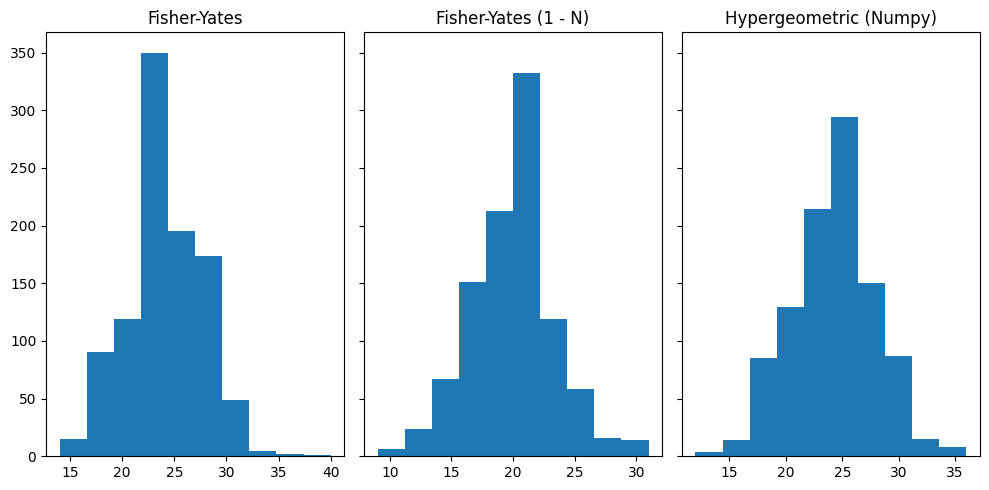

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

K = 1000

M_amostra = 500 # Quantidade de elementos da hypergeometric
N_amostra = 60 # Instâncias de sucesso
n_amostra = 200 # Amostra retirada da "urna"

def fisherYates(M,N, n):
  fracassos = np.zeros(M - N)
  sucessos = np.ones(N)

  pop = np.concatenate((fracassos, sucessos))
  for i in range(n):
    j = np.random.randint(i, len(pop))
    element = pop[i]
    pop[i] = pop[j]
    pop[j] = element
  return sum(pop[:n])

def fisherYates2(M,N, n):
  fracassos = np.zeros(M - N)
  sucessos = np.ones(N)

  pop = np.concatenate((fracassos, sucessos))
  for i in range(n):
    j = np.random.randint(0, len(pop))
    element = pop[i]
    pop[i] = pop[j]
    pop[j] = element
  return sum(pop[:n])




amostra = []
amostra_1N = []
amostra_np = np.random.hypergeometric(N_amostra, (M_amostra - N_amostra), n_amostra, size=K)
for _ in range(K):
  amostra.append(fisherYates(M_amostra,N_amostra,n_amostra))
  amostra_1N.append(fisherYates2(M_amostra,N_amostra,n_amostra))

fig, axes = plt.subplots(1, 3, sharey=True, tight_layout=True, figsize=(10, 5))

axes[0].hist(amostra)
axes[0].set(title="Fisher-Yates")

axes[1].hist(amostra_1N)
axes[1].set(title="Fisher-Yates (1 - N)")

axes[2].hist(amostra_np)
axes[2].set(title="Hypergeometric (Numpy)")

plt.show()

# Exercício 3

É intuitivo esperar que, quando o tamanho total da população $M+N$ cresce muito em relação ao tamanho da amostra $n$, o fato de a amostragem ser feita sem reposição passe a ter pouca importância, pois retirar um elemento altera muito pouco a composição da população restante. Nesse caso, cada retirada deve se comportar aproximadamente como um ensaio de Bernoulli independente, com probabilidade de sucesso

$$
p=\frac{N}{M+N}.
$$

Assim, esperamos que a distribuição hipergeométrica com parâmetros $M,N,n$ se aproxime de uma distribuição binomial com parâmetros $n$ e $p$.

Compare numericamente essas duas distribuições para valores crescentes de $M$ e $N$, mantendo aproximadamente constante a proporção

$$
\frac{N}{M+N}\to p,
$$

e mantendo $n$ fixo. Verifique, por meio de simulações, se a aproximação pela distribuição binomial melhora à medida que $M+N$ aumenta.


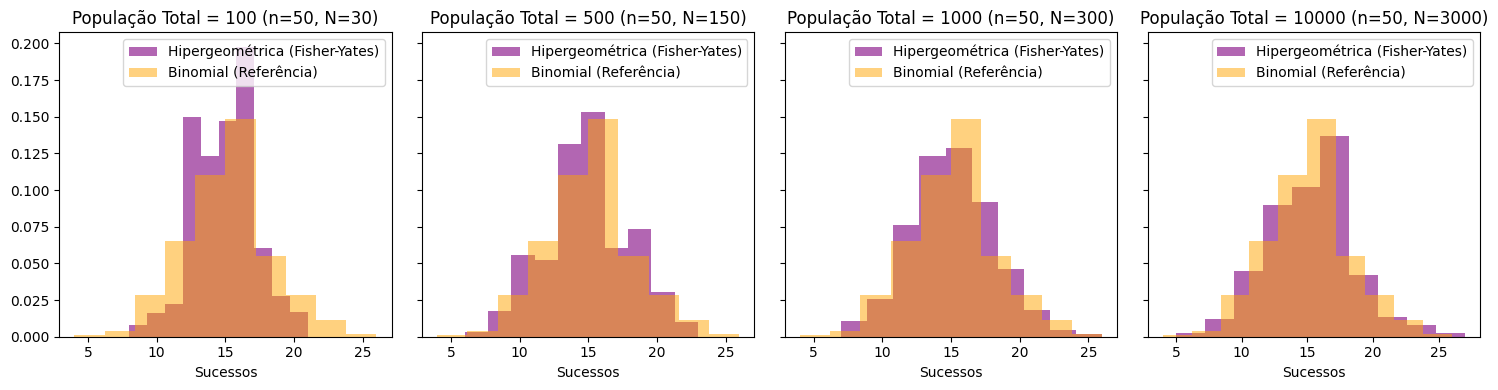

In [ ]:
K = 1000

n = 50 # tamanho da amostra fixo
p = 0.3 # Proporção fixa

# Tamanhos crescentes para a população total (M + N)
tamanhos_populacao = [100, 500, 1000, 10000]

# Implementação recursiva:
def binomialRecursiva(n, p):
    u = np.random.uniform(0, 1)

    i = 0
    pi = (1 - p)**n
    F = pi

    while u > F:
      pi = ((n - i)/(i + 1)) * (p/(1-p)) * pi
      i += 1
      F += pi
    return i

# Geração de amostras:
def amostraBinomialRecursiva(n, M, p):
  amostras = []
  for i in range(M):
    amostras.append(binomialRecursiva(n, p))
  return amostras


amostra_binomial = amostraBinomialRecursiva(n, K, p)

fig, axes = plt.subplots(1, len(tamanhos_populacao), figsize=(15, 4), sharey=True)

for i in range(len(tamanhos_populacao)):
  M = tamanhos_populacao[i]
  N = round(M * p)

  amostra_hiper = []
  for _ in range(K):
    amostra_hiper.append(fisherYates(M, N, n))

  axes[i].hist(amostra_hiper, alpha=0.6, label='Hipergeométrica (Fisher-Yates)', color='purple', density=True)
  axes[i].hist(amostra_binomial, alpha=0.5, label='Binomial (Referência)', color='orange', density=True)
  axes[i].set(title="População Total = {} (n={}, N={})".format(M, n, N))
  axes[i].set_xlabel("Sucessos")
  axes[i].legend()

plt.tight_layout()
plt.show()

